In [32]:
from langgraph.graph import StateGraph,START,END 
from langchain_mistralai import ChatMistralAI
from dotenv import load_dotenv
from typing import TypedDict, Literal
from pydantic import BaseModel , Field
from dotenv import load_dotenv

In [33]:
load_dotenv()

True

In [34]:
model = ChatMistralAI(model_name="ministral-3b-latest", temperature=0.7)

### defining Schema (output format)

In [35]:
class SentimentSchema(BaseModel):
    sentiment: Literal["positive", "negative", "neutral"] = Field(..., description="The sentiment of the revie.")

In [36]:
class negativeSentimentSchema(BaseModel):
    issueType:Literal["UX", "Performance", "Bug", "Other"] = Field(..., description="The type of issue reported in the review.")
    tone:Literal["Angry", "Frustrated", "Disappointed", "Confused"] = Field(..., description="The tone of the review.")
    urgency:Literal["High", "Medium", "Low"] = Field(..., description="The urgency of the issue reported in the review.")
    

In [37]:
structured_model1 = model.with_structured_output(SentimentSchema)
structured_model2 = model.with_structured_output(negativeSentimentSchema)

#### checking model structure

In [38]:
prompt = """what is the sentiment of the following review?  - software too good """ 
structured_model1.invoke(prompt).sentiment

'positive'

In [39]:
class ReviewState(TypedDict):
    review: str
    sentiment: Literal["positive", "negative"]
    diagnosis: dict
    response: str

In [ ]:
def find_sentiment(state: ReviewState):
    prompt =f'for the following review, find the sentiment and return it in a json format with key as sentiment and value as positive or negative. Review: {state["review"]}'
    sentiment = structured_model1.invoke(prompt).sentiment

    return {
        'sentiment': sentiment
    }

def check_sentiment(state: ReviewState):
    if state['sentiment'] == 'positive':
        return 'positive response'
       
    else:
        return 'run_diagnosis'

def positive_response(state: ReviewState):
    prompt = f"""You are a support assistant. Based on the following review, generate a response to the user. Review: {state["review"]}. Please provide a helpful and empathetic response."""
    response = model.invoke(prompt).content
    return {
        'response': response
    }
def run_diagnosis(state: ReviewState):
    prompt = f'for the following review, find the issue type, tone and urgency and return it in a json format with keys as issueType, tone and urgency. Review: {state["review"]}'
    response = structured_model2.invoke(prompt)
    return {
        'diagnosis': response.model_dump()
    }
def negative_response(state: ReviewState):
    # Updated issue_type to issueType
    prompt = f"""You are a support assistant. Based on the following review and diagnosis, generate a response to the user. Review: {state["diagnosis"]["issueType"]}, sounded {state["diagnosis"]["tone"]} and has an urgency of {state["diagnosis"]["urgency"]}. Please provide a helpful and empathetic response.
    write a empathtic , hekpful resolution message."""
    response = model.invoke(prompt).content
    return {
        'response': response
    }


In [50]:
graph = StateGraph(ReviewState)

graph.add_node('find_sentiment', find_sentiment)
graph.add_node('positive_response', positive_response)
graph.add_node('run_diagnosis', run_diagnosis)
graph.add_node('negative_response', negative_response)

graph.add_edge(START, 'find_sentiment')
graph.add_edge('find_sentiment', 'positive_response')
graph.add_edge('find_sentiment', 'run_diagnosis')
graph.add_edge('positive_response', END)
graph.add_edge('run_diagnosis', 'negative_response')
graph.add_edge('negative_response', END)
workflow = graph.compile()

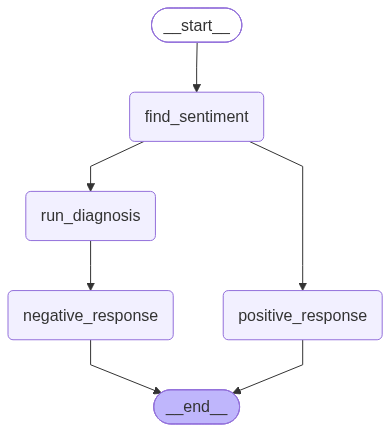

In [51]:
workflow

In [52]:
initial_state = {
    'review': 'The software is too slow and crashes frequently. It is very frustrating to use.',

}

workflow.invoke(initial_state)

{'review': 'The software is too slow and crashes frequently. It is very frustrating to use.',
 'sentiment': 'negative',
 'diagnosis': {'issueType': 'Performance',
  'tone': 'Frustrated',
  'urgency': 'High'},
 'response': 'Here’s a compassionate and helpful response you could use:\n\n---\n**Subject:** Supporting You Through This Moment\n\nHi [Name],\n\nI hear how much you’re feeling right now, and I want you to know that your feelings are completely valid. It sounds like you’re dealing with something that’s really weighing on you—both the frustration and the urgency make sense, especially when things feel overwhelming. That’s not something to be dismissed.\n\nI’m here to listen, and I’d like to help however I can. Would it help to:\n- **Talk through what’s on your mind?** (Even just venting can sometimes ease the pressure.)\n- **Break things down into smaller steps?** (Sometimes clarity can reduce the sense of urgency.)\n- **Connect you with resources?** (Whether that’s tools, people, 